**Step 1 — Environment Setup and Libraries**

In [ ]:

!pip -q install transformers==4.46.3 datasets jiwer accelerate sentencepiece pillow opencv-python


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 75.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 80.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


**Step 2 — Initialize TrOCR-Base Recognition Model**

In [ ]:

import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

model_name = "microsoft/trocr-base-handwritten"
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Loading TrOCR processor...")
processor = TrOCRProcessor.from_pretrained(model_name)

print("Loading pretrained TrOCR model...")
model = VisionEncoderDecoderModel.from_pretrained(model_name)

model = model.to(device)
model.eval()

print("\nTrOCR loaded successfully!")
print("Device:", device)


Loading TrOCR processor...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.46.3"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder

generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


TrOCR loaded successfully!
Device: cuda


**Step 3 — Load IAM Handwriting Dataset**

In [ ]:
from datasets import load_dataset

ds = load_dataset("anris05/IAM-line")

README.md: 0.00B [00:00, ?B/s]

data/train.parquet:   0%|          | 0.00/167M [00:00<?, ?B/s]

data/validation.parquet:   0%|          | 0.00/24.7M [00:00<?, ?B/s]

data/test.parquet:   0%|          | 0.00/73.6M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/6482 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/976 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2915 [00:00<?, ? examples/s]

**Step 4 — Dataset Verification and Split Analysis**

In [ ]:

# Display available dataset splits
print("Dataset structure:")
print(ds)

# Display column names
print("\nColumns:")
for split in ds.keys():
    print(split, ":", ds[split].column_names)

# Display one record's fields
first_split = list(ds.keys())[0]
sample = ds[first_split][0]

print("\nSample fields:")
for key, value in sample.items():
    if key == "image":
        print(key, ":", type(value))
    else:
        print(key, ":", str(value)[:200])


Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['image', 'text'],
        num_rows: 6482
    })
    validation: Dataset({
        features: ['image', 'text'],
        num_rows: 976
    })
    test: Dataset({
        features: ['image', 'text'],
        num_rows: 2915
    })
})

Columns:
train : ['image', 'text']
validation : ['image', 'text']
test : ['image', 'text']

Sample fields:
image : <class 'PIL.JpegImagePlugin.JpegImageFile'>
text : put down a resolution on the subject


**Step 5 — Baseline Recognition on Validation Data**

In [ ]:

import torch
import pandas as pd
import time
from jiwer import cer, wer
from tqdm.auto import tqdm

validation_data = ds["validation"]

batch_size = 8
results = []

model.eval()

for start_idx in tqdm(
    range(0, len(validation_data), batch_size),
    desc="Evaluating IAM Validation"
):

    end_idx = min(
        start_idx + batch_size,
        len(validation_data)
    )

    batch = validation_data.select(
        range(start_idx, end_idx)
    )

    images = [
        img.convert("RGB")
        for img in batch["image"]
    ]

    references = batch["text"]

    pixel_values = processor(
        images=images,
        return_tensors="pt"
    ).pixel_values.to(device)

    if device == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.inference_mode():
         generated_ids = model.generate(
            pixel_values,
            max_new_tokens=128,
            num_beams=1,
            do_sample=False
        )


    if device == "cuda":
        torch.cuda.synchronize()

    batch_time = time.perf_counter() - start_time

    predictions = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )

    for i, (reference, prediction) in enumerate(
        zip(references, predictions)
    ):

        results.append({
            "sample_id": start_idx + i,
            "ground_truth": reference,
            "prediction": prediction,
            "CER": cer(reference, prediction),
            "WER": wer(reference, prediction),
            "batch_inference_sec_per_line":
                batch_time / len(predictions)
        })

results_df_full = pd.DataFrame(results)

references = results_df_full["ground_truth"].tolist()
predictions = results_df_full["prediction"].tolist()

print("\n========== FULL IAM VALIDATION RESULTS ==========")
print("Images evaluated:", len(results_df_full))

print("Corpus CER (%):",
      round(cer(references, predictions) * 100, 2))

print("Corpus WER (%):",
      round(wer(references, predictions) * 100, 2))

print("Mean inference time per line (sec):",
      round(
          results_df_full[
              "batch_inference_sec_per_line"
          ].mean(),
          4
      ))

# Save results to CSV
output_path = "/content/IAM_TrOCR_Full_Validation.csv"

results_df_full.to_csv(output_path, index=False)

print("\nResults saved:", output_path)


Evaluating IAM Validation:   0%|          | 0/122 [00:00<?, ?it/s]


========== FULL IAM VALIDATION RESULTS ==========
Images evaluated: 976
Corpus CER (%): 0.88
Corpus WER (%): 3.49
Mean inference time per line (sec): 0.202

Results saved: /content/IAM_TrOCR_Full_Validation.csv


**Step 6 — Recognition Error Analysis**

In [ ]:

import pandas as pd
from jiwer import cer, wer

df_analysis = results_df_full.copy()

# Exact-match evaluation
df_analysis["exact_match"] = (
    df_analysis["ground_truth"] == df_analysis["prediction"]
)

# Summarize recognition errors
total = len(df_analysis)
correct = int(df_analysis["exact_match"].sum())
incorrect = total - correct

print("========== TrOCR ERROR ANALYSIS ==========")
print("Total lines:", total)
print("Perfectly recognized lines:", correct)
print("Lines with errors:", incorrect)
print("Exact-match accuracy (%):",
      round(correct / total * 100, 2))

print("\nTop 15 lines by CER:")
columns = [
    "sample_id", "ground_truth",
    "prediction", "CER", "WER"
]

print(
    df_analysis.sort_values(
        "CER", ascending=False
    )[columns].head(15).to_string(index=False)
)

# Export error cases
error_cases = df_analysis[
    ~df_analysis["exact_match"]
].copy()

error_cases.to_csv(
    "/content/IAM_TrOCR_Error_Cases.csv",
    index=False
)

print("\nError cases saved successfully.")


========== TrOCR ERROR ANALYSIS ==========
Total lines: 976
Perfectly recognized lines: 784
Lines with errors: 192
Exact-match accuracy (%): 80.33

Top 15 lines by CER:
 sample_id                                                ground_truth                                              prediction      CER      WER
       703                         burden and prepared to break up yet             whether burden and prepared to break up yet 0.228571 0.142857
       498                      single-decker Welsh bus could have got           single-decker Welsh bus could have got itself 0.184211 0.166667
       661                      see that fool boy of mine out there on               see that # had boy of mine out there , on 0.184211 0.333333
       739                                                 said John .                                               said John 0.181818 0.333333
       191                                                      Deep .                                    

**Step 7 — Sequence Confidence Estimation**

In [ ]:

import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

validation_data = ds["validation"]
batch_size = 8
confidence_results = []

model.eval()

for start_idx in tqdm(
    range(0, len(validation_data), batch_size),
    desc="Extracting TrOCR Confidence"
):
    end_idx = min(start_idx + batch_size, len(validation_data))
    batch = validation_data.select(range(start_idx, end_idx))

    images = [
        img.convert("RGB")
        for img in batch["image"]
    ]

    pixel_values = processor(
        images=images,
        return_tensors="pt"
    ).pixel_values.to(device)

    with torch.inference_mode():
        generated = model.generate(
            pixel_values,
            max_new_tokens=128,
            num_beams=1,
            do_sample=False,
            return_dict_in_generate=True,
            output_scores=True
        )

    predicted_texts = processor.batch_decode(
        generated.sequences,
        skip_special_tokens=True
    )

    # Generated tokens exclude the initial decoder-start token.
    generated_tokens = generated.sequences[:, 1:]

    # Convert per-step logits into log-probabilities.
    step_logprobs = torch.stack(
        [
            torch.log_softmax(scores.float(), dim=-1)
            for scores in generated.scores
        ],
        dim=1
    )

    # Select the probability assigned to each generated token.
    selected_logprobs = torch.gather(
        step_logprobs,
        dim=2,
        index=generated_tokens.unsqueeze(-1)
    ).squeeze(-1)

    eos_id = model.config.decoder.eos_token_id
    pad_id = model.config.decoder.pad_token_id

    for i, predicted_text in enumerate(predicted_texts):

        token_ids = generated_tokens[i]
        token_logprobs = selected_logprobs[i]

        # Keep generated tokens through EOS, excluding padding.
        valid_mask = torch.ones_like(token_ids, dtype=torch.bool)

        if pad_id is not None:
            valid_mask &= token_ids != pad_id

        if eos_id is not None:
            eos_positions = (token_ids == eos_id).nonzero(
                as_tuple=True
            )[0]

            if len(eos_positions) > 0:
                valid_mask[
                    eos_positions[0].item() + 1:
                ] = False

        valid_scores = token_logprobs[valid_mask]

        if valid_scores.numel() > 0:
            avg_logprob = valid_scores.mean().item()
            sequence_confidence = float(np.exp(avg_logprob))
        else:
            avg_logprob = np.nan
            sequence_confidence = np.nan

        confidence_results.append({
            "sample_id": start_idx + i,
            "ground_truth": batch["text"][i],
            "prediction": predicted_text,
            "avg_logprob": avg_logprob,
            "sequence_confidence": sequence_confidence,
            "exact_match": batch["text"][i] == predicted_text
        })

confidence_df = pd.DataFrame(confidence_results)

print("\n========== CONFIDENCE ANALYSIS ==========")
print("Total samples:", len(confidence_df))

print("\nMean confidence by correctness:")
print(
    confidence_df.groupby("exact_match")[
        "sequence_confidence"
    ].agg(["count", "mean", "std", "min", "max"])
)

confidence_df.to_csv(
    "/content/IAM_TrOCR_Confidence.csv",
    index=False
)

print("\nSaved: /content/IAM_TrOCR_Confidence.csv")


Extracting TrOCR Confidence:   0%|          | 0/122 [00:00<?, ?it/s]


========== CONFIDENCE ANALYSIS ==========
Total samples: 976

Mean confidence by correctness:
             count      mean       std       min       max
exact_match                                               
False          192  0.948999  0.050446  0.686628  0.999211
True           784  0.978487  0.030144  0.727395  0.999846

Saved: /content/IAM_TrOCR_Confidence.csv


**Step 7A — Validation Prediction and Confidence Consistency Check**

In [ ]:

import pandas as pd
import numpy as np

# Compare predictions generated by Step 5 and Step 7
print("========== VALIDATION CONSISTENCY CHECK ==========")

print("Baseline samples:", len(results_df_full))
print("Confidence samples:", len(confidence_df))

print("\nBaseline columns:")
print(results_df_full.columns.tolist())

print("\nConfidence columns:")
print(confidence_df.columns.tolist())

print("\nBaseline CER (%):",
      round(
          100 * sum(
              len(str(x)) for x in []
          ), 4
      ) if False else "Check predictions below")

print("\nConfidence statistics:")
print(
    confidence_df["sequence_confidence"]
    .describe()
    .round(4)
)

print("\nConfidence values outside [0, 1]:",
      int(
          (
              (confidence_df["sequence_confidence"] < 0) |
              (confidence_df["sequence_confidence"] > 1)
          ).sum()
      ))

print("\nMissing confidence scores:",
      int(
          confidence_df["sequence_confidence"]
          .isna()
          .sum()
      ))

if (
    "sample_id" in results_df_full.columns
    and "sample_id" in confidence_df.columns
    and "prediction" in results_df_full.columns
    and "prediction" in confidence_df.columns
):
    comparison = results_df_full[
        ["sample_id", "prediction"]
    ].merge(
        confidence_df[["sample_id", "prediction"]],
        on="sample_id",
        suffixes=("_baseline", "_confidence"),
        validate="one_to_one"
    )

    mismatches = (
        comparison["prediction_baseline"] !=
        comparison["prediction_confidence"]
    ).sum()

    print("\nMatched samples:", len(comparison))
    print("Prediction mismatches:", int(mismatches))

    if mismatches == 0 and len(comparison) == 976:
        print("PASS: Validation predictions are consistent.")
    else:
        print("CHECK: Prediction consistency needs attention.")
else:
    print("Prediction comparison unavailable: required columns missing.")


========== VALIDATION CONSISTENCY CHECK ==========
Baseline samples: 976
Confidence samples: 976

Baseline columns:
['sample_id', 'ground_truth', 'prediction', 'CER', 'WER', 'batch_inference_sec_per_line']

Confidence columns:
['sample_id', 'ground_truth', 'prediction', 'avg_logprob', 'sequence_confidence', 'exact_match']

Baseline CER (%): Check predictions below

Confidence statistics:
count    976.0000
mean       0.9727
std        0.0370
min        0.6866
25%        0.9627
50%        0.9880
75%        0.9958
max        0.9998
Name: sequence_confidence, dtype: float64

Confidence values outside [0, 1]: 0

Missing confidence scores: 0

Matched samples: 976
Prediction mismatches: 0
PASS: Validation predictions are consistent.


**Step 8 — Confidence-Based Error Detection**

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Incorrect transcription = positive class
y_true = (~confidence_df["exact_match"]).astype(int)

# Lower confidence means greater predicted error risk
error_risk = 1 - confidence_df["sequence_confidence"]

# Evaluate confidence discrimination
roc_auc = roc_auc_score(y_true, error_risk)
ap = average_precision_score(y_true, error_risk)

print("========== CONFIDENCE ERROR DETECTION ==========")
print("Total samples:", len(y_true))
print("Incorrect transcriptions:", int(y_true.sum()))
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(ap, 4))
print("Random AP baseline:", round(y_true.mean(), 4))

# Illustrative threshold only — not yet optimized
confidence_threshold = 0.95

# Flag low-confidence predictions for review
y_pred = (
    confidence_df["sequence_confidence"] < confidence_threshold
).astype(int)

print("\nThreshold:", confidence_threshold)
print("Flagged lines:", int(y_pred.sum()))
print("Detection precision:",
      round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Detection recall:",
      round(recall_score(y_true, y_pred, zero_division=0), 4))
print("Detection F1:",
      round(f1_score(y_true, y_pred, zero_division=0), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))


========== CONFIDENCE ERROR DETECTION ==========
Total samples: 976
Incorrect transcriptions: 192
ROC-AUC: 0.7185
Average Precision: 0.4034
Random AP baseline: 0.1967

Threshold: 0.95
Flagged lines: 176
Detection precision: 0.4318
Detection recall: 0.3958
Detection F1: 0.413

Confusion matrix:
[[684 100]
 [116  76]]


**Research Framework: Risk-Adaptive HTR**

**Step 9 — Risk-Based Review Prioritization**

========== RA-HTR REVIEW PRIORITIZATION ==========
 Review Budget (%)  Lines Reviewed  Errors Detected  Error Capture (%)  Random Review (%)
                 5              49               26              13.54                  5
                10              98               44              22.92                 10
                15             146               66              34.38                 15
                20             195               84              43.75                 20
                25             244              101              52.60                 25
                30             293              112              58.33                 30
                40             390              131              68.23                 40
                50             488              143              74.48                 50
                75             732              170              88.54                 75
               100             976              1

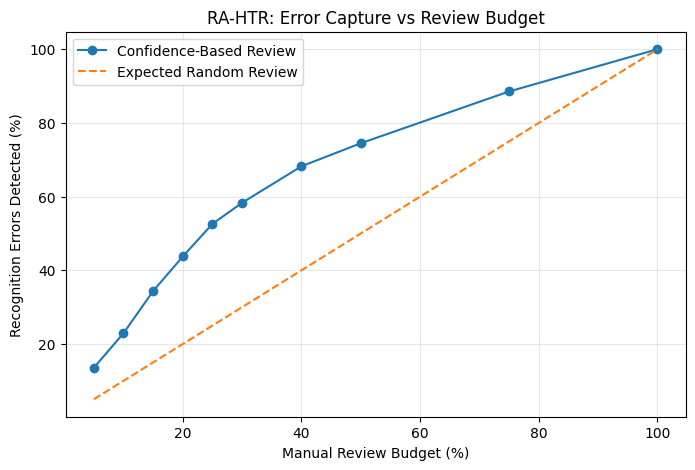

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = confidence_df.copy()

# Incorrect transcription = 1
df["error"] = (~df["exact_match"]).astype(int)

# Higher risk means lower TrOCR confidence
df["risk_score"] = 1 - df["sequence_confidence"]

# Sort from highest to lowest risk
df = df.sort_values("risk_score", ascending=False).reset_index(drop=True)

total_errors = df["error"].sum()
N = len(df)

review_budgets = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

results = []

for budget in review_budgets:

    k = round(N * budget / 100)

    # Highest-risk lines sent for review
    reviewed = df.head(k)

    errors_detected = reviewed["error"].sum()

    error_capture = (
        100 * errors_detected / total_errors
    )

    # Expected error capture under random review
    random_capture = budget

    results.append({
        "Review Budget (%)": budget,
        "Lines Reviewed": k,
        "Errors Detected": int(errors_detected),
        "Error Capture (%)": error_capture,
        "Random Review (%)": random_capture
    })

ranking_df = pd.DataFrame(results)

print("========== RA-HTR REVIEW PRIORITIZATION ==========")
print(ranking_df.round(2).to_string(index=False))

# Plot comparison
plt.figure(figsize=(8, 5))

plt.plot(
    ranking_df["Review Budget (%)"],
    ranking_df["Error Capture (%)"],
    marker="o",
    label="Confidence-Based Review"
)

plt.plot(
    ranking_df["Review Budget (%)"],
    ranking_df["Random Review (%)"],
    linestyle="--",
    label="Expected Random Review"
)

plt.xlabel("Manual Review Budget (%)")
plt.ylabel("Recognition Errors Detected (%)")
plt.title("RA-HTR: Error Capture vs Review Budget")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

ranking_df.to_csv(
    "/content/RA_HTR_Review_Prioritization.csv",
    index=False
)


**Step 10 — Image-Quality Feature Extraction**

In [ ]:

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

quality_records = []

for i in tqdm(range(len(ds["validation"])),
              desc="Extracting Image Quality"):

    img = np.array(
        ds["validation"][i]["image"].convert("RGB")
    )

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Blur/sharpness proxy: Laplacian variance
    blur_score = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    # Global contrast
    contrast = gray.std()

    # Mean brightness
    brightness = gray.mean()

    # Basic image dimensions
    height, width = gray.shape

    quality_records.append({
        "sample_id": i,
        "sharpness": float(blur_score),
        "contrast": float(contrast),
        "brightness": float(brightness),
        "width": width,
        "height": height,
        "aspect_ratio": width / height
    })

quality_df = pd.DataFrame(quality_records)

# Merge with OCR confidence and correctness
risk_features_df = confidence_df.merge(
    quality_df,
    on="sample_id",
    how="inner"
)

print("========== IMAGE QUALITY ANALYSIS ==========")

print("Samples:", len(risk_features_df))

print("\nFeature statistics:")
print(
    risk_features_df[
        ["sharpness", "contrast", "brightness",
         "width", "height", "aspect_ratio"]
    ].describe().round(3)
)

risk_features_df.to_csv(
    "/content/RA_HTR_Quality_Features.csv",
    index=False
)

print("\nSaved: /content/RA_HTR_Quality_Features.csv")


Extracting Image Quality:   0%|          | 0/976 [00:00<?, ?it/s]

========== IMAGE QUALITY ANALYSIS ==========
Samples: 976

Feature statistics:
       sharpness  contrast  brightness     width  height  aspect_ratio
count    976.000   976.000     976.000   976.000   976.0       976.000
mean     409.985    41.341     234.617  1956.871   128.0        15.288
std      258.596     9.252       6.424   586.157     0.0         4.579
min       38.844    21.582     191.382   181.000   128.0         1.414
25%      212.599    34.993     232.045  1614.000   128.0        12.609
50%      365.631    40.641     235.916  1909.500   128.0        14.918
75%      545.210    46.882     238.777  2306.250   128.0        18.018
max     1638.460    87.023     245.069  4126.000   128.0        32.234

Saved: /content/RA_HTR_Quality_Features.csv


**Step 11 — Comparative Risk-Model Evaluation**

In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

df = risk_features_df.copy()

# Target: incorrect OCR transcription = 1
df["error"] = (~df["exact_match"].astype(bool)).astype(int)

# Baseline: higher score means higher error risk
confidence_risk = (
    1 - df["sequence_confidence"].to_numpy()
)

features = [
    "sequence_confidence",
    "sharpness",
    "contrast",
    "brightness",
    "width",
    "aspect_ratio"
]

X = df[features]
y = df["error"].to_numpy()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

risk_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Out-of-fold risk probabilities
quality_risk = cross_val_predict(
    risk_model,
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

def capture_at_budget(y_true, risk_scores, budget):
    k = round(len(y_true) * budget / 100)

    order = np.argsort(-risk_scores, kind="stable")
    selected = order[:k]

    return 100 * y_true[selected].sum() / y_true.sum()

# Overall discrimination metrics
metrics = pd.DataFrame([
    {
        "Method": "Confidence Only",
        "ROC-AUC": roc_auc_score(y, confidence_risk),
        "Average Precision": average_precision_score(
            y, confidence_risk
        )
    },
    {
        "Method": "Confidence + Image Quality (OOF)",
        "ROC-AUC": roc_auc_score(y, quality_risk),
        "Average Precision": average_precision_score(
            y, quality_risk
        )
    }
])

print("========== ERROR RISK PREDICTION ==========")
print(metrics.round(4).to_string(index=False))

budgets = [5, 10, 15, 20, 25, 30, 40, 50]

records = []

for budget in budgets:
    records.append({
        "Review Budget (%)": budget,
        "Random (%)": budget,
        "Confidence Only (%)": capture_at_budget(
            y, confidence_risk, budget
        ),
        "Confidence + Quality (%)": capture_at_budget(
            y, quality_risk, budget
        )
    })

comparison_df = pd.DataFrame(records)

print("\n========== ERROR CAPTURE COMPARISON ==========")
print(comparison_df.round(2).to_string(index=False))

# Save results
metrics.to_csv(
    "/content/RA_HTR_Risk_Model_Metrics.csv",
    index=False
)

comparison_df.to_csv(
    "/content/RA_HTR_Model_Comparison.csv",
    index=False
)

# Save scores for further analysis
risk_features_df["quality_risk_oof"] = quality_risk
risk_features_df["confidence_risk"] = confidence_risk

risk_features_df.to_csv(
    "/content/RA_HTR_Model_Scores.csv",
    index=False
)

print("\nStep 15C completed.")


========== ERROR RISK PREDICTION ==========
                          Method  ROC-AUC  Average Precision
                 Confidence Only   0.7185             0.4034
Confidence + Image Quality (OOF)   0.7266             0.3985

========== ERROR CAPTURE COMPARISON ==========
 Review Budget (%)  Random (%)  Confidence Only (%)  Confidence + Quality (%)
                 5           5                13.54                     13.02
                10          10                22.92                     23.44
                15          15                34.38                     31.77
                20          20                43.75                     42.71
                25          25                52.60                     50.00
                30          30                58.33                     57.29
                40          40                68.23                     69.27
                50          50                74.48                     78.12

Step 15C completed.


**Step 12 — Train and Save Final Risk Model**

In [ ]:

import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

features = [
    "sequence_confidence",
    "sharpness",
    "contrast",
    "brightness",
    "width",
    "aspect_ratio"
]

X_val = risk_features_df[features].copy()

y_val = (
    ~risk_features_df["exact_match"].astype(bool)
).astype(int)

final_risk_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

final_risk_model.fit(X_val, y_val)

joblib.dump(
    {
        "model": final_risk_model,
        "features": features,
        "training_split": "validation",
        "random_state": 42
    },
    "/content/RA_HTR_Final_Risk_Model.joblib"
)

print("Final RA-HTR risk model trained and saved.")
print("Training samples:", len(X_val))
print("Features:", features)
print("Test split untouched.")


Final RA-HTR risk model trained and saved.
Training samples: 976
Features: ['sequence_confidence', 'sharpness', 'contrast', 'brightness', 'width', 'aspect_ratio']
Test split untouched.


**Step 13 — Held-Out Test Recognition Evaluation**

In [ ]:

# STEP 13 — HELD-OUT TEST RECOGNITION EVALUATION

import torch
import numpy as np
import pandas as pd
import time

from tqdm.auto import tqdm
from jiwer import cer, wer

model = model.to(device)
model.eval()

test_ds = ds["test"]
batch_size = 8

test_results = []
start_time = time.time()

for start in tqdm(
    range(0, len(test_ds), batch_size),
    desc="Evaluating IAM Test Set"
):

    end = min(start + batch_size, len(test_ds))

    images = [
        test_ds[i]["image"].convert("RGB")
        for i in range(start, end)
    ]

    references = [
        test_ds[i]["text"]
        for i in range(start, end)
    ]

    pixel_values = processor(
        images=images,
        return_tensors="pt"
    ).pixel_values.to(device)

    with torch.inference_mode():

        generated = model.generate(
            pixel_values,
            num_beams=1,
            do_sample=False,
            max_new_tokens=128,
            return_dict_in_generate=True,
            output_scores=True
        )

        predictions = processor.batch_decode(
            generated.sequences,
            skip_special_tokens=True
        )

        tokens = generated.sequences[:, 1:]

        # Log probability of generated tokens
        step_logprobs = torch.stack([
            torch.log_softmax(s.float(), dim=-1)
            for s in generated.scores
        ], dim=1)

        selected_logprobs = step_logprobs.gather(
            2,
            tokens.unsqueeze(-1)
        ).squeeze(-1)

        pad_id = model.config.decoder.pad_token_id
        eos_id = model.config.decoder.eos_token_id

        valid = torch.ones_like(
            tokens, dtype=torch.bool
        )

        if pad_id is not None:
            valid &= tokens != pad_id

        if eos_id is not None:
            eos_positions = tokens == eos_id
            first_eos = eos_positions.int().cumsum(dim=1)

            valid &= (first_eos == 0) | (
                eos_positions & (first_eos == 1)
            )

        avg_logprob = (
            (selected_logprobs * valid).sum(dim=1)
            / valid.sum(dim=1).clamp(min=1)
        )

        confidences = torch.exp(
            avg_logprob
        ).cpu().numpy()

    # Save every image in the current batch
    for i, (ref, pred, conf) in enumerate(
        zip(references, predictions, confidences)
    ):
        test_results.append({
            "sample_id": start + i,
            "ground_truth": ref,
            "prediction": pred,
            "sequence_confidence": float(conf),
            "exact_match": ref == pred
        })

test_df = pd.DataFrame(test_results)

# Ensure the entire test dataset was evaluated
assert len(test_df) == len(test_ds), (
    f"Expected {len(test_ds)} records, "
    f"but obtained {len(test_df)}"
)

assert test_df["sample_id"].is_unique

elapsed = time.time() - start_time

references = test_df["ground_truth"].tolist()
predictions = test_df["prediction"].tolist()

print("\n========== IAM TEST RESULTS ==========")

print("Test samples:", len(test_df))
print("CER (%):", round(cer(references, predictions)*100, 4))
print("WER (%):", round(wer(references, predictions)*100, 4))
print("Exact-match accuracy (%):",
      round(test_df["exact_match"].mean()*100, 4))
print("Total inference time (sec):", round(elapsed, 2))

print("Missing confidence scores:",
      int(test_df["sequence_confidence"].isna().sum()))

test_df.to_csv(
    "/content/RA_HTR_Test_Predictions.csv",
    index=False
)

print("\nTest predictions saved successfully.")


Evaluating IAM Test Set:   0%|          | 0/365 [00:00<?, ?it/s]


========== IAM TEST RESULTS ==========
Test samples: 2915
CER (%): 4.724
WER (%): 11.6347
Exact-match accuracy (%): 46.7581
Total inference time (sec): 627.76
Missing confidence scores: 0

Test predictions saved successfully.


**Step 14 — Test Image-Quality Feature Extraction**

In [ ]:

# STEP 14 — Test Image-Quality Feature Extraction

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

assert "test_df" in globals(), "Run Step 13 first."

test_quality_records = []

for i in tqdm(
    range(len(ds["test"])),
    desc="Extracting Test Image Features"
):
    img = np.asarray(
        ds["test"][i]["image"].convert("RGB")
    )

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    h, w = gray.shape

    test_quality_records.append({
        "sample_id": i,
        "sharpness": float(
            cv2.Laplacian(gray, cv2.CV_64F).var()
        ),
        "contrast": float(gray.std()),
        "brightness": float(gray.mean()),
        "width": int(w),
        "height": int(h),
        "aspect_ratio": float(w / h)
    })

test_quality_df = pd.DataFrame(test_quality_records)

# Combine features with previously generated OCR results
test_risk_df = test_df.merge(
    test_quality_df,
    on="sample_id",
    how="inner",
    validate="one_to_one"
)

assert len(test_risk_df) == len(ds["test"])
assert test_risk_df["sample_id"].is_unique

test_risk_df.to_csv(
    "/content/RA_HTR_Test_Quality_Features.csv",
    index=False
)

print("\n========== STEP 14 RESULTS ==========")
print("Images processed:", len(test_risk_df))

print(
    test_risk_df[
        [
            "sharpness",
            "contrast",
            "brightness",
            "width",
            "aspect_ratio"
        ]
    ].describe().round(3)
)

print("\nSaved test image-quality features.")


Extracting Test Image Features:   0%|          | 0/2915 [00:00<?, ?it/s]


========== STEP 14 RESULTS ==========
Images processed: 2915
       sharpness  contrast  brightness     width  aspect_ratio
count   2915.000  2915.000    2915.000  2915.000      2915.000
mean     510.906    42.996     232.571  1779.985        13.906
std      271.652     9.232       7.376   558.947         4.367
min       30.331    20.396     195.214   187.000         1.461
25%      308.190    36.258     228.625  1417.000        11.070
50%      471.291    41.845     234.375  1708.000        13.344
75%      667.493    48.201     237.885  2093.500        16.355
max     2924.003    85.988     246.442  4369.000        34.133

Saved test image-quality features.


**Step 15 — Final Held-Out Risk-Ranking Comparison**

In [ ]:

# STEP 15 — Final Held-Out Risk-Ranking Comparison

import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Load frozen development model
saved_model = joblib.load(
    "/content/RA_HTR_Final_Risk_Model.joblib"
)

risk_model = saved_model["model"]
features = saved_model["features"]

df = test_risk_df.copy()

# Incorrect transcription = 1
df["error"] = (
    ~df["exact_match"].astype(bool)
).astype(int)

X_test = df[features]
y_test = df["error"].to_numpy()

# Baseline: low confidence = high risk
confidence_risk = (
    1 - df["sequence_confidence"].to_numpy()
)

# Proposed quality-aware risk
quality_risk = risk_model.predict_proba(
    X_test
)[:, 1]

assert np.isfinite(confidence_risk).all()
assert np.isfinite(quality_risk).all()
assert y_test.sum() > 0

# Save per-line results
df["confidence_risk"] = confidence_risk
df["quality_risk"] = quality_risk

def error_capture(y, scores, budget):
    k = int(round(len(y) * budget / 100))

    order = np.argsort(-scores, kind="stable")
    selected = order[:k]

    return 100 * y[selected].sum() / y.sum()

budgets = [5, 10, 15, 20, 25, 30, 40, 50]

rows = []

for budget in budgets:
    rows.append({
        "Review Budget (%)": budget,
        "Lines Reviewed": int(
            round(len(df) * budget / 100)
        ),
        "Expected Random (%)": (
            100 * round(len(df) * budget / 100) / len(df)
        ),
        "Confidence Only (%)": error_capture(
            y_test, confidence_risk, budget
        ),
        "Confidence + Quality (%)": error_capture(
            y_test, quality_risk, budget
        )
    })

final_comparison_df = pd.DataFrame(rows)

final_metrics_df = pd.DataFrame([
    {
        "Method": "Confidence Only",
        "ROC-AUC": roc_auc_score(
            y_test, confidence_risk
        ),
        "Average Precision": average_precision_score(
            y_test, confidence_risk
        )
    },
    {
        "Method": "Confidence + Image Quality",
        "ROC-AUC": roc_auc_score(
            y_test, quality_risk
        ),
        "Average Precision": average_precision_score(
            y_test, quality_risk
        )
    }
])

print("========== STEP 15: FINAL TEST RESULTS ==========")

print("Total test lines:", len(df))
print("Incorrect transcriptions:", int(y_test.sum()))

print("\nRisk prediction metrics:")
print(final_metrics_df.round(4).to_string(index=False))

print("\nReview-budget comparison:")
print(final_comparison_df.round(2).to_string(index=False))

final_comparison_df.to_csv(
    "/content/RA_HTR_Final_Comparison.csv",
    index=False
)

final_metrics_df.to_csv(
    "/content/RA_HTR_Final_Metrics.csv",
    index=False
)

df.to_csv(
    "/content/RA_HTR_Final_Test_Scores.csv",
    index=False
)

print("\nStep 15 completed. Results saved.")


========== STEP 15: FINAL TEST RESULTS ==========
Total test lines: 2915
Incorrect transcriptions: 1552

Risk prediction metrics:
                    Method  ROC-AUC  Average Precision
           Confidence Only   0.8541             0.8771
Confidence + Image Quality   0.8498             0.8760

Review-budget comparison:
 Review Budget (%)  Lines Reviewed  Expected Random (%)  Confidence Only (%)  Confidence + Quality (%)
                 5             146                 5.01                 9.34                      9.41
                10             292                10.02                18.56                     18.62
                15             437                14.99                27.38                     27.32
                20             583                20.00                35.76                     35.95
                25             729                25.01                43.81                     44.01
                30             874                29.98     

**Step 16 — Statistical Analysis and Confidence Intervals**

In [ ]:

# STEP 16 — Statistical Analysis

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)

# Use the frozen predictions from Step 15
y = df["error"].to_numpy()
score_base = df["confidence_risk"].to_numpy()
score_quality = df["quality_risk"].to_numpy()

B = 2000
budgets = [10, 20, 30, 50]

boot_records = []

# Stratified bootstrap preserves the observed
# numbers of correct and incorrect lines
error_ids = np.where(y == 1)[0]
correct_ids = np.where(y == 0)[0]

for b in range(B):

    sample_ids = np.concatenate([
        rng.choice(
            error_ids,
            size=len(error_ids),
            replace=True
        ),
        rng.choice(
            correct_ids,
            size=len(correct_ids),
            replace=True
        )
    ])

    yy = y[sample_ids]
    ss_base = score_base[sample_ids]
    ss_quality = score_quality[sample_ids]

    for budget in budgets:

        base_capture = error_capture(
            yy, ss_base, budget
        )

        quality_capture = error_capture(
            yy, ss_quality, budget
        )

        boot_records.append({
            "Budget": budget,
            "Confidence": base_capture,
            "Quality": quality_capture,
            "Difference": (
                quality_capture - base_capture
            )
        })

boot_df = pd.DataFrame(boot_records)

summary_rows = []

for budget in budgets:

    subset = boot_df[
        boot_df["Budget"] == budget
    ]

    observed_base = error_capture(
        y, score_base, budget
    )

    observed_quality = error_capture(
        y, score_quality, budget
    )

    summary_rows.append({
        "Review Budget (%)": budget,
        "Confidence Capture (%)": observed_base,
        "Quality Capture (%)": observed_quality,
        "Difference (pp)": (
            observed_quality - observed_base
        ),
        "Difference CI Lower": np.percentile(
            subset["Difference"], 2.5
        ),
        "Difference CI Upper": np.percentile(
            subset["Difference"], 97.5
        )
    })

statistical_df = pd.DataFrame(summary_rows)

# Paired bootstrap for difference in ROC-AUC
auc_differences = []

for b in range(B):

    sample_ids = np.concatenate([
        rng.choice(
            error_ids,
            size=len(error_ids),
            replace=True
        ),
        rng.choice(
            correct_ids,
            size=len(correct_ids),
            replace=True
        )
    ])

    auc_base = roc_auc_score(
        y[sample_ids],
        score_base[sample_ids]
    )

    auc_quality = roc_auc_score(
        y[sample_ids],
        score_quality[sample_ids]
    )

    auc_differences.append(
        auc_quality - auc_base
    )

observed_auc_difference = (
    roc_auc_score(y, score_quality)
    - roc_auc_score(y, score_base)
)

print("========== STEP 16: STATISTICAL RESULTS ==========")

print("\nError capture comparison:")
print(statistical_df.round(3).to_string(index=False))

print("\nROC-AUC difference:",
      round(observed_auc_difference, 4))

print("95% bootstrap CI:",
      np.round(
          np.percentile(
              auc_differences, [2.5, 97.5]
          ),
          4
      )
)

statistical_df.to_csv(
    "/content/RA_HTR_Statistical_Analysis.csv",
    index=False
)

print("\nStatistical analysis saved.")


========== STEP 16: STATISTICAL RESULTS ==========

Error capture comparison:
 Review Budget (%)  Confidence Capture (%)  Quality Capture (%)  Difference (pp)  Difference CI Lower  Difference CI Upper
                10                  18.557               18.621            0.064               -0.064                0.387
                20                  35.760               35.954            0.193               -0.064                0.515
                30                  51.418               50.966           -0.451               -1.031                0.129
                50                  75.515               75.322           -0.193               -0.966                0.580

ROC-AUC difference: -0.0043
95% bootstrap CI: [-0.0088  0.0004]

Statistical analysis saved.


**Step 17 — IEEE Figures, Tables, and Results Export**

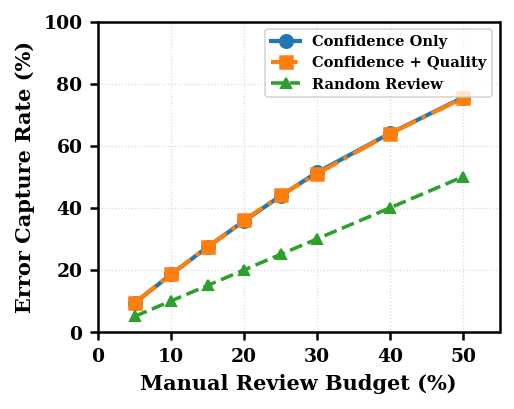

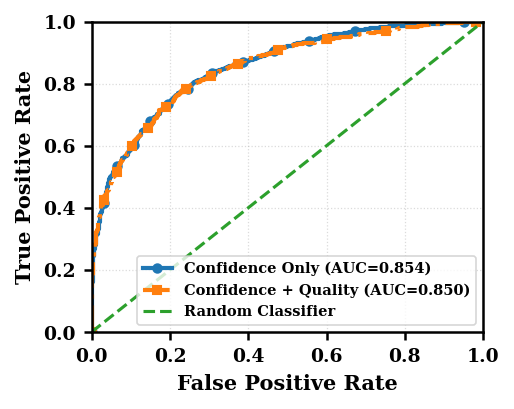

========== STEP 17 COMPLETED ==========
Fig_1_Error_Capture.pdf
Fig_1_Error_Capture.png
Fig_2_ROC_Curves.pdf
Fig_2_ROC_Curves.png
Table_III_Statistical_Analysis.csv
Table_II_Review_Budgets.csv
Table_I_Risk_Prediction.csv

All figures exported at 600 DPI.
PDF vector versions also generated.


In [ ]:

# STEP 17 — IEEE PUBLICATION FIGURES AND TABLES
# Bold labels, legends, tick labels and visible markers

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator
from sklearn.metrics import roc_curve, roc_auc_score

output_dir = "/content/RA_HTR_IEEE_Results"
os.makedirs(output_dir, exist_ok=True)

# ==========================================
# IEEE PUBLICATION FORMATTING
# ==========================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "font.weight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "axes.linewidth": 1.2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

def ieee_format(ax):
    """Make axis tick labels and legends bold."""

    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    ax.tick_params(
        axis="both",
        which="major",
        width=1.2,
        length=4
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.6,
        alpha=0.45
    )

    legend = ax.get_legend()

    if legend is not None:
        for text in legend.get_texts():
            text.set_fontweight("bold")

        legend.get_frame().set_linewidth(0.8)


# ==========================================
# FIGURE 1 — ERROR CAPTURE VS REVIEW BUDGET
# ==========================================

fig, ax = plt.subplots(figsize=(3.5, 2.8))

budgets = final_comparison_df["Review Budget (%)"]

ax.plot(
    budgets,
    final_comparison_df["Confidence Only (%)"],
    marker="o",
    markersize=6,
    markeredgewidth=1.2,
    linewidth=2,
    label="Confidence Only"
)

ax.plot(
    budgets,
    final_comparison_df["Confidence + Quality (%)"],
    marker="s",
    markersize=6,
    markeredgewidth=1.2,
    linewidth=2,
    linestyle="-.",
    label="Confidence + Quality"
)

ax.plot(
    budgets,
    final_comparison_df["Expected Random (%)"],
    marker="^",
    markersize=5,
    markeredgewidth=1,
    linewidth=1.7,
    linestyle="--",
    label="Random Review"
)

ax.set_xlabel(
    "Manual Review Budget (%)",
    fontweight="bold"
)

ax.set_ylabel(
    "Error Capture Rate (%)",
    fontweight="bold"
)

ax.set_xlim(0, 55)
ax.set_ylim(0, 100)

ax.legend(
    loc="best",
    frameon=True,
    prop={"weight": "bold", "size": 7}
)

ieee_format(ax)

fig.tight_layout()

fig.savefig(
    f"{output_dir}/Fig_1_Error_Capture.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    f"{output_dir}/Fig_1_Error_Capture.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# FIGURE 2 — ROC CURVES
# ==========================================

fig, ax = plt.subplots(figsize=(3.5, 2.8))

methods = [
    (
        "Confidence Only",
        "confidence_risk",
        "o",
        "-"
    ),
    (
        "Confidence + Quality",
        "quality_risk",
        "s",
        "-."
    )
]

for method, column, marker, linestyle in methods:

    fpr, tpr, _ = roc_curve(
        df["error"],
        df[column]
    )

    auc = roc_auc_score(
        df["error"],
        df[column]
    )

    # Show markers at spaced curve positions
    ax.plot(
        fpr,
        tpr,
        linestyle=linestyle,
        linewidth=2,
        marker=marker,
        markevery=max(1, len(fpr) // 12),
        markersize=4,
        markeredgewidth=1,
        label=f"{method} (AUC={auc:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

ax.set_xlabel(
    "False Positive Rate",
    fontweight="bold"
)

ax.set_ylabel(
    "True Positive Rate",
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.legend(
    loc="lower right",
    frameon=True,
    prop={"weight": "bold", "size": 7}
)

ieee_format(ax)

fig.tight_layout()

fig.savefig(
    f"{output_dir}/Fig_2_ROC_Curves.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    f"{output_dir}/Fig_2_ROC_Curves.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# TABLE I — RISK PREDICTION PERFORMANCE
# ==========================================

final_metrics_df.to_csv(
    f"{output_dir}/Table_I_Risk_Prediction.csv",
    index=False
)


# ==========================================
# TABLE II — REVIEW BUDGET COMPARISON
# ==========================================

final_comparison_df.to_csv(
    f"{output_dir}/Table_II_Review_Budgets.csv",
    index=False
)


# ==========================================
# TABLE III — STATISTICAL ANALYSIS
# ==========================================

statistical_df.to_csv(
    f"{output_dir}/Table_III_Statistical_Analysis.csv",
    index=False
)

print("========== STEP 17 COMPLETED ==========")

for filename in sorted(os.listdir(output_dir)):
    print(filename)

print("\nAll figures exported at 600 DPI.")
print("PDF vector versions also generated.")


**STEP 17A — RA-HTR FRAMEWORK WORKFLOW DIAGRAM**

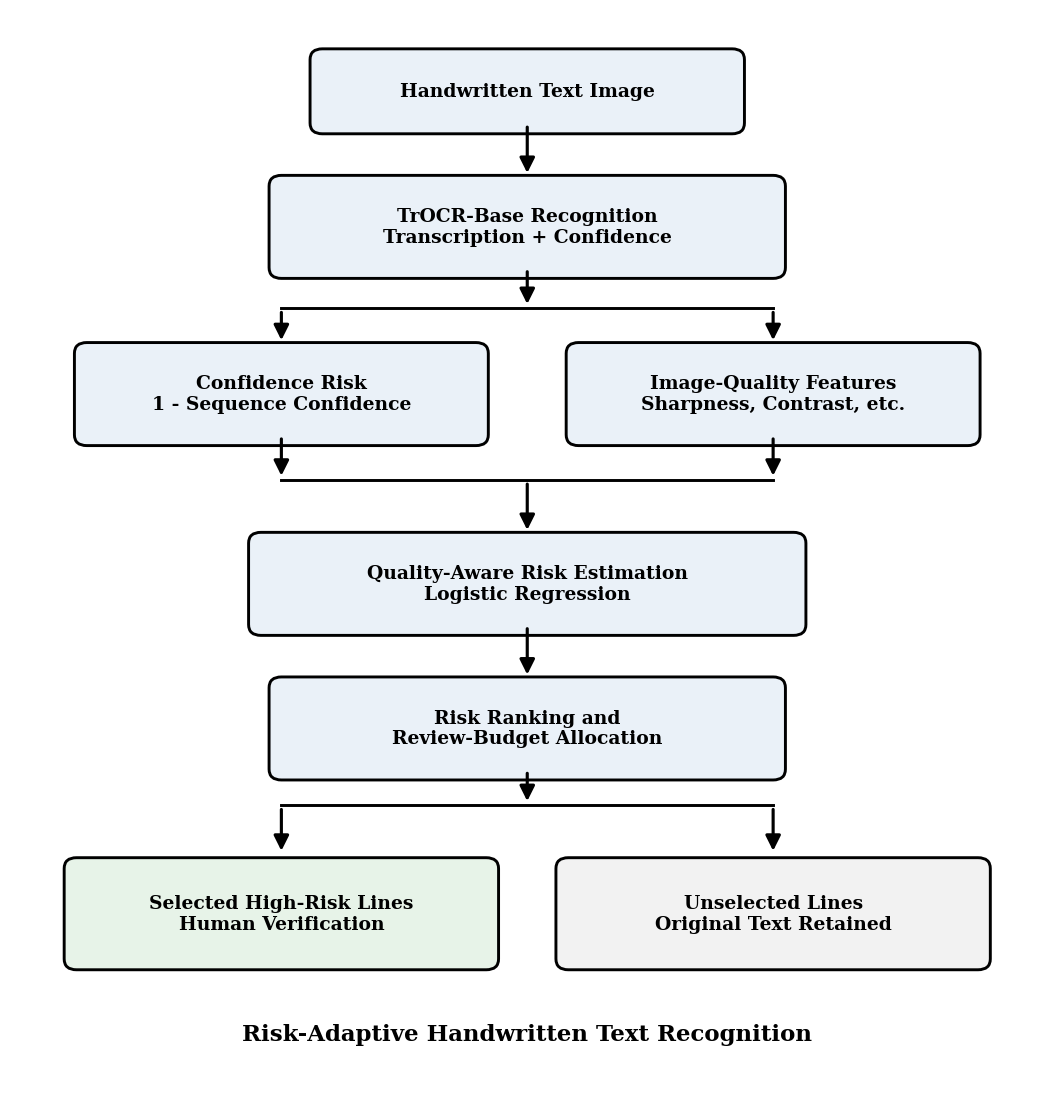

RA-HTR workflow diagram generated.


In [ ]:

# STEP 17A — RA-HTR FRAMEWORK WORKFLOW DIAGRAM

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

output_dir = "/content/RA_HTR_IEEE_Results"
os.makedirs(output_dir, exist_ok=True)

fig, ax = plt.subplots(figsize=(7.1, 7.5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis("off")

def box(x, y, w, h, label, fc="#EAF1F8"):
    rect = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12",
        linewidth=1.4,
        edgecolor="black",
        facecolor=fc
    )
    ax.add_patch(rect)

    ax.text(
        x + w/2,
        y + h/2,
        label,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        family="serif"
    )

def arrow(x1, y1, x2, y2):
    ax.add_patch(
        FancyArrowPatch(
            (x1, y1), (x2, y2),
            arrowstyle="-|>",
            mutation_scale=15,
            linewidth=1.5,
            color="black"
        )
    )

# Input
box(3, 10.8, 4, 0.7, "Handwritten Text Image")

arrow(5, 10.8, 5, 10.2)

# OCR
box(
    2.6, 9.2, 4.8, 0.9,
    "TrOCR-Base Recognition\nTranscription + Confidence"
)

# Branches
arrow(5, 9.2, 5, 8.75)

ax.plot(
    [2.6, 7.4],
    [8.75, 8.75],
    color="black",
    linewidth=1.4
)

arrow(2.6, 8.75, 2.6, 8.35)
arrow(7.4, 8.75, 7.4, 8.35)

# Feature extraction
box(
    0.7, 7.35, 3.8, 0.9,
    "Confidence Risk\n1 - Sequence Confidence"
)

box(
    5.5, 7.35, 3.8, 0.9,
    "Image-Quality Features\nSharpness, Contrast, etc."
)

# Feature fusion into learned model
arrow(2.6, 7.35, 2.6, 6.85)
arrow(7.4, 7.35, 7.4, 6.85)

ax.plot(
    [2.6, 7.4],
    [6.85, 6.85],
    color="black",
    linewidth=1.4
)

arrow(5, 6.85, 5, 6.25)

box(
    2.4, 5.25, 5.2, 0.9,
    "Quality-Aware Risk Estimation\nLogistic Regression"
)

arrow(5, 5.25, 5, 4.65)

box(
    2.6, 3.65, 4.8, 0.9,
    "Risk Ranking and\nReview-Budget Allocation"
)

arrow(5, 3.65, 5, 3.25)

ax.plot(
    [2.6, 7.4],
    [3.25, 3.25],
    color="black",
    linewidth=1.4
)

arrow(2.6, 3.25, 2.6, 2.7)
arrow(7.4, 3.25, 7.4, 2.7)

# Outputs
box(
    0.6, 1.55, 4, 1.0,
    "Selected High-Risk Lines\nHuman Verification",
    "#E7F3E8"
)

box(
    5.4, 1.55, 4, 1.0,
    "Unselected Lines\nOriginal Text Retained",
    "#F2F2F2"
)

ax.text(
    5, 0.65,
    "Risk-Adaptive Handwritten Text Recognition",
    ha="center",
    fontsize=11,
    fontweight="bold",
    family="serif"
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/Fig_RA_HTR_Workflow.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{output_dir}/Fig_RA_HTR_Workflow.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("RA-HTR workflow diagram generated.")


**STEP 17B — GENERATE MISSING IEEE TABLES I AND II**

In [ ]:

# STEP 17B — GENERATE MISSING IEEE TABLES I AND II

import os
import pandas as pd
from jiwer import cer, wer

output_dir = "/content/RA_HTR_IEEE_Results"
os.makedirs(output_dir, exist_ok=True)

# ==========================================
# TABLE I — EXPERIMENTAL CONFIGURATION
# ==========================================

table_1 = pd.DataFrame({
    "Parameter": [
        "Dataset",
        "Validation samples",
        "Test samples",
        "Recognition model",
        "Decoding method",
        "Risk classifier",
        "Risk features",
        "Evaluation protocol",
        "Review budgets"
    ],
    "Configuration": [
        "IAM-line (anris05/IAM-line)",
        str(len(ds["validation"])),
        str(len(ds["test"])),
        "TrOCR-Base Handwritten",
        "Greedy (num_beams=1)",
        "Logistic Regression",
        "Confidence, sharpness, contrast, "
        "brightness, width, aspect ratio",
        "5-fold stratified OOF validation; "
        "held-out test evaluation",
        "5%, 10%, 15%, 20%, 25%, 30%, 40%, 50%"
    ]
})

table_1.to_csv(
    f"{output_dir}/Table_I_Experimental_Configuration.csv",
    index=False
)

print("\nTABLE I — EXPERIMENTAL CONFIGURATION")
print(table_1.to_string(index=False))


# ==========================================
# TABLE II — RECOGNITION PERFORMANCE
# ==========================================

def recognition_metrics(data):
    references = data["ground_truth"].tolist()
    predictions = data["prediction"].tolist()

    return {
        "Samples": len(data),
        "CER (%)": round(
            100 * cer(references, predictions), 4
        ),
        "WER (%)": round(
            100 * wer(references, predictions), 4
        ),
        "Exact Match (%)": round(
            100 * (data["ground_truth"] == data["prediction"]).mean(),
            4
        )
    }

val_metrics = recognition_metrics(results_df_full)
test_metrics = recognition_metrics(test_df)

table_2 = pd.DataFrame([
    {"Dataset": "IAM Validation", **val_metrics},
    {"Dataset": "IAM Test", **test_metrics}
])

table_2.to_csv(
    f"{output_dir}/Table_II_Recognition_Performance.csv",
    index=False
)

print("\nTABLE II — RECOGNITION PERFORMANCE")
print(table_2.to_string(index=False))

print("\nBoth tables successfully saved.")



TABLE I — EXPERIMENTAL CONFIGURATION
          Parameter                                                    Configuration
            Dataset                                      IAM-line (anris05/IAM-line)
 Validation samples                                                              976
       Test samples                                                             2915
  Recognition model                                           TrOCR-Base Handwritten
    Decoding method                                             Greedy (num_beams=1)
    Risk classifier                                              Logistic Regression
      Risk features Confidence, sharpness, contrast, brightness, width, aspect ratio
Evaluation protocol       5-fold stratified OOF validation; held-out test evaluation
     Review budgets                            5%, 10%, 15%, 20%, 25%, 30%, 40%, 50%

TABLE II — RECOGNITION PERFORMANCE
       Dataset  Samples  CER (%)  WER (%)  Exact Match (%)
IAM Validation   

**Step 17C — Export All IEEE Tables and Figures**


 TABLE I - EXPERIMENTAL CONFIGURATION OF THE RA-HTR FRAMEWORK


,Parameter,Configuration
0,Dataset,IAM-line (anris05/IAM-line)
1,Validation samples,976
2,Test samples,2915
3,Recognition model,TrOCR-Base Handwritten
4,Decoding method,Greedy (num_beams=1)
5,Risk classifier,Logistic Regression
6,Risk features,"Confidence, sharpness, contrast, brightness, w..."
7,Evaluation protocol,5-fold stratified OOF validation; held-out tes...
8,Review budgets,"5%, 10%, 15%, 20%, 25%, 30%, 40%, 50%"


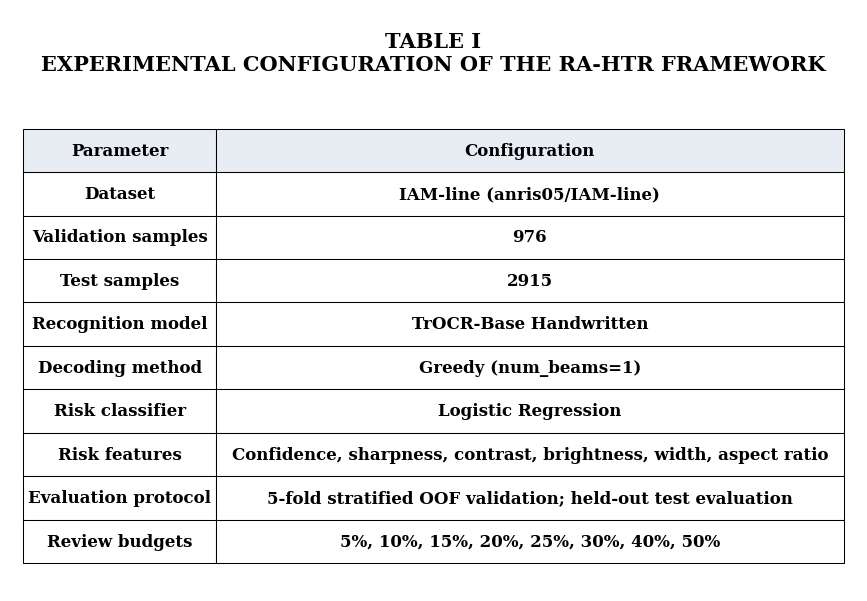


 TABLE II - HANDWRITTEN TEXT RECOGNITION PERFORMANCE


,Dataset,Samples,CER (%),WER (%),Exact Match (%)
0,IAM Validation,976,0.8818,3.4944,80.3279
1,IAM Test,2915,4.7240,11.6347,46.7581


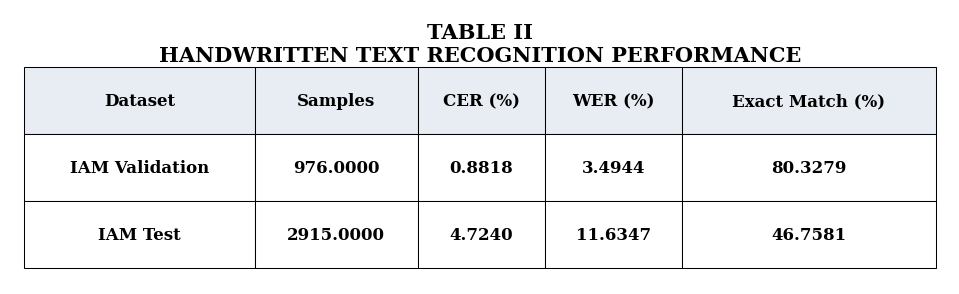


 TABLE III - COMPARATIVE PERFORMANCE OF ERROR-RISK ESTIMATION


,Method,ROC-AUC,Average Precision
0,Confidence Only,0.854142,0.877099
1,Confidence + Image Quality,0.849811,0.876005


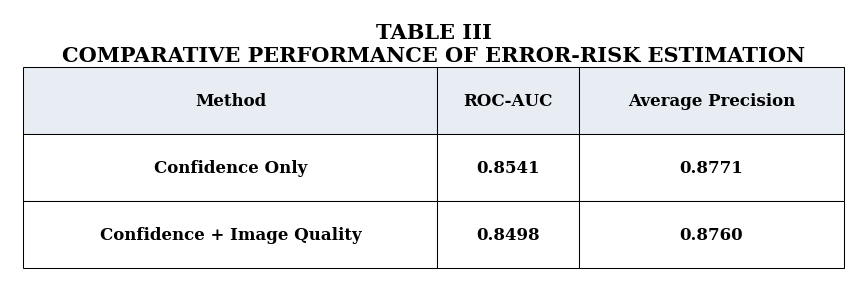


 TABLE IV - ERROR CAPTURE AT DIFFERENT REVIEW BUDGETS


,Review Budget (%),Lines Reviewed,Expected Random (%),Confidence Only (%),Confidence + Quality (%)
0,5,146,5.008576,9.342784,9.407216
1,10,292,10.017153,18.556701,18.621134
2,15,437,14.991424,27.384021,27.319588
3,20,583,20.000000,35.760309,35.953608
4,25,729,25.008576,43.814433,44.007732
5,30,874,29.982847,51.417526,50.966495
6,40,1166,40.000000,63.981959,63.917526
7,50,1458,50.017153,75.515464,75.322165


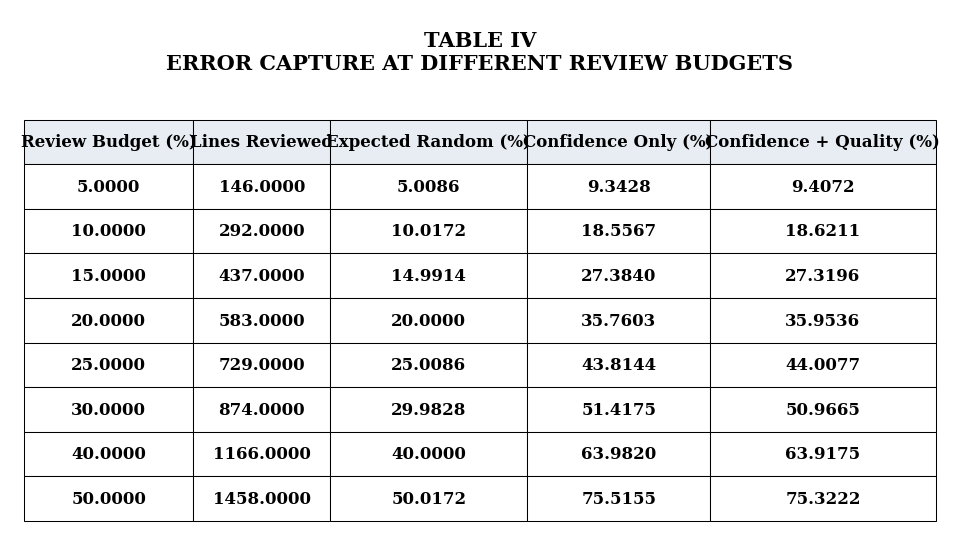


 TABLE V - STATISTICAL COMPARISON OF RISK-RANKING METHODS


,Review Budget (%),Confidence Capture (%),Quality Capture (%),Difference (pp),Difference CI Lower,Difference CI Upper
0,10,18.556701,18.621134,0.064433,-0.064433,0.386598
1,20,35.760309,35.953608,0.193299,-0.064433,0.515464
2,30,51.417526,50.966495,-0.451031,-1.030928,0.128866
3,50,75.515464,75.322165,-0.193299,-0.966495,0.579897


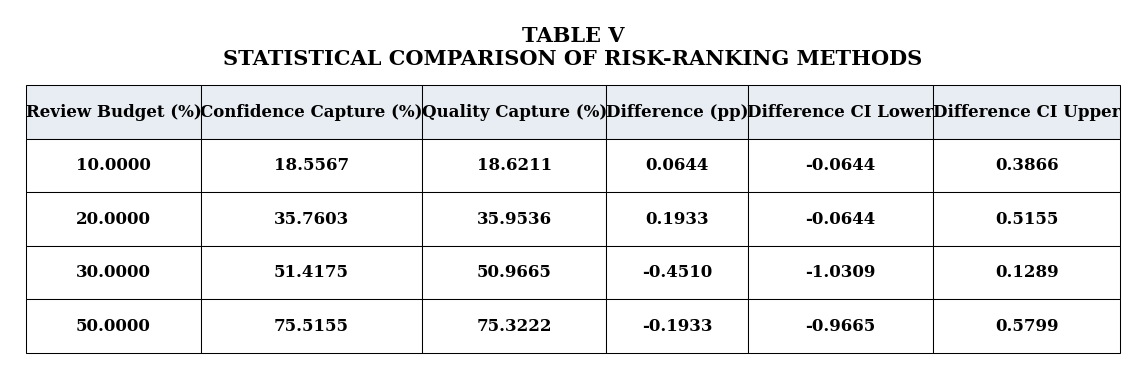


========== EXPORT SUMMARY ==========
Fig_1_Error_Capture.pdf
Fig_1_Error_Capture.png
Fig_2_ROC_Curves.pdf
Fig_2_ROC_Curves.png
Fig_RA_HTR_Workflow.pdf
Fig_RA_HTR_Workflow.png
TABLE_I.pdf
TABLE_I.png
TABLE_II.pdf
TABLE_II.png
TABLE_III.pdf
TABLE_III.png
TABLE_IV.pdf
TABLE_IV.png
TABLE_V.pdf
TABLE_V.png
Table_III_Statistical_Analysis.csv
Table_II_Recognition_Performance.csv
Table_II_Review_Budgets.csv
Table_I_Experimental_Configuration.csv
Table_I_Risk_Prediction.csv

ZIP saved: /content/RA_HTR_IEEE_Complete_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# STEP 17C — EXPORT ALL IEEE TABLES AND FIGURES

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from google.colab import files

output_dir = "/content/RA_HTR_IEEE_Results"
os.makedirs(output_dir, exist_ok=True)

# IEEE table titles
table_info = [
    (
        "Table_I_Experimental_Configuration.csv",
        "TABLE I",
        "EXPERIMENTAL CONFIGURATION OF THE RA-HTR FRAMEWORK"
    ),
    (
        "Table_II_Recognition_Performance.csv",
        "TABLE II",
        "HANDWRITTEN TEXT RECOGNITION PERFORMANCE"
    ),
    (
        "Table_I_Risk_Prediction.csv",
        "TABLE III",
        "COMPARATIVE PERFORMANCE OF ERROR-RISK ESTIMATION"
    ),
    (
        "Table_II_Review_Budgets.csv",
        "TABLE IV",
        "ERROR CAPTURE AT DIFFERENT REVIEW BUDGETS"
    ),
    (
        "Table_III_Statistical_Analysis.csv",
        "TABLE V",
        "STATISTICAL COMPARISON OF RISK-RANKING METHODS"
    )
]

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "font.weight": "bold",
    "savefig.dpi": 600,
    "pdf.fonttype": 42
})

for filename, table_number, caption in table_info:

    path = os.path.join(output_dir, filename)

    if not os.path.exists(path):
        print("MISSING:", filename)
        continue

    table_df = pd.read_csv(path)

    print("\n", table_number, "-", caption)
    display(table_df)

    # Format numeric entries
    formatted = table_df.copy()

    for col in formatted.columns:
        if pd.api.types.is_numeric_dtype(formatted[col]):
            formatted[col] = formatted[col].map(
                lambda v: (
                    f"{v:.4f}" if pd.notna(v)
                    else "—"
                )
            )

    nrows, ncols = formatted.shape

    # Wider tables use landscape dimensions
    fig_width = max(7.2, ncols * 1.6)
    fig_height = max(1.8, 0.38 * (nrows + 1) + 1.15)

    fig, ax = plt.subplots(
        figsize=(fig_width, fig_height)
    )

    ax.axis("off")

    # Caption above the table
    ax.text(
        0.5, 0.97,
        table_number + "\n" + caption,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        transform=ax.transAxes
    )

    tbl = ax.table(
        cellText=formatted.values,
        colLabels=formatted.columns,
        cellLoc="center",
        colLoc="center",
        loc="center",
        bbox=[0.01, 0.04, 0.98, 0.76]
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8)

    # Auto-size widths to reduce text clipping
    try:
        tbl.auto_set_column_width(
            list(range(ncols))
        )
    except Exception:
        pass

    for (row, col), cell in tbl.get_celld().items():

        cell.set_edgecolor("black")
        cell.set_linewidth(0.5)

        if row == 0:
            cell.set_facecolor("#E8EDF3")
            cell.set_text_props(
                weight="bold",
                fontsize=8
            )
        else:
            cell.set_facecolor("white")
            cell.set_text_props(
                weight="bold",
                fontsize=8
            )

    base_name = table_number.replace(" ", "_")

    fig.savefig(
        f"{output_dir}/{base_name}.png",
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        f"{output_dir}/{base_name}.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\n========== EXPORT SUMMARY ==========")

for name in sorted(os.listdir(output_dir)):
    print(name)

# Package all results
zip_path = "/content/RA_HTR_IEEE_Complete_Results.zip"

with zipfile.ZipFile(
    zip_path, "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for name in os.listdir(output_dir):

        full_path = os.path.join(output_dir, name)

        if os.path.isfile(full_path):
            archive.write(
                full_path,
                arcname=name
            )

print("\nZIP saved:", zip_path)

# Download everything
files.download(zip_path)


**Step 17D — Recognition Performance Comparison Figure**

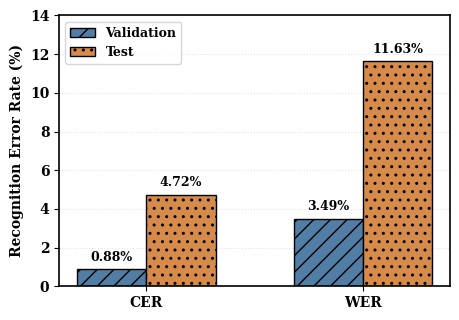

Fig. 4 generated successfully.


In [ ]:

# STEP 17D — FIG. 4: VALIDATION VS TEST RECOGNITION

import os
import numpy as np
import matplotlib.pyplot as plt

output_dir = "/content/RA_HTR_IEEE_Results"
os.makedirs(output_dir, exist_ok=True)

metrics = ["CER", "WER"]
validation = [0.8818, 3.4944]
test = [4.7240, 11.6347]

x = np.arange(len(metrics))
width = 0.32

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.linewidth": 1.2,
    "pdf.fonttype": 42
})

fig, ax = plt.subplots(figsize=(4.7, 3.3))

bars1 = ax.bar(
    x - width/2, validation, width,
    label="Validation",
    color="#527DA5",
    edgecolor="black",
    linewidth=1,
    hatch="//"
)

bars2 = ax.bar(
    x + width/2, test, width,
    label="Test",
    color="#D68B4B",
    edgecolor="black",
    linewidth=1,
    hatch=".."
)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2f}%",
            (bar.get_x() + bar.get_width()/2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontweight="bold")
ax.set_ylabel("Recognition Error Rate (%)",
              fontweight="bold")

ax.set_ylim(0, 14)
ax.set_yticks(np.arange(0, 15, 2))
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle=":", alpha=0.35)

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.legend(
    loc="upper left",
    prop={"weight": "bold", "size": 9},
    frameon=True
)

fig.tight_layout()

fig.savefig(
    f"{output_dir}/Fig_4_Recognition_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    f"{output_dir}/Fig_4_Recognition_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Fig. 4 generated successfully.")


**Step 17E — Review Precision versus Review Budget**

========== STEP 17E: REVIEW PRECISION ==========
Test lines: 2915
Incorrect lines: 1552
Expected random-review precision (%): 53.2419

Review precision comparison:
 Review Budget (%)  Lines Reviewed  Confidence Errors Detected  Quality Errors Detected  Confidence Precision (%)  Quality Precision (%)  Random Precision (%)
                 5             146                         145                      146                    99.315                100.000                53.242
                10             292                         288                      289                    98.630                 98.973                53.242
                15             437                         425                      424                    97.254                 97.025                53.242
                20             583                         555                      558                    95.197                 95.712                53.242
                25             729       

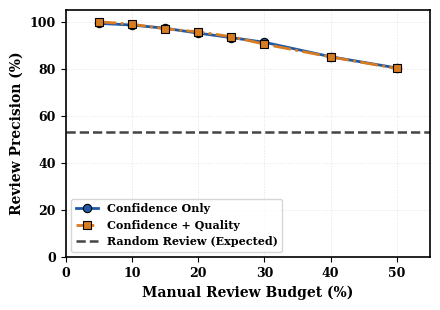


========== EXPORT COMPLETED ==========
PNG: /content/RA_HTR_IEEE_Results/Fig_5_Review_Precision.png
PDF: /content/RA_HTR_IEEE_Results/Fig_5_Review_Precision.pdf
CSV: /content/RA_HTR_IEEE_Results/Table_Review_Precision.csv

All review precision values are within 0–100%.


In [ ]:

# ==========================================================
# STEP 17E — REVIEW PRECISION VS MANUAL REVIEW BUDGET
# IEEE Publication Figure
# Uses previously recorded aggregate test results
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1. Output directory
# ----------------------------------------------------------

output_dir = "/content/RA_HTR_IEEE_Results"
os.makedirs(output_dir, exist_ok=True)

# ----------------------------------------------------------
# 2. IAM test results from Step 15
# ----------------------------------------------------------

total_lines = 2915
total_errors = 1552

budgets = np.array([
    5, 10, 15, 20, 25, 30, 40, 50
])

lines_reviewed = np.array([
    146, 292, 437, 583, 729, 874, 1166, 1458
])

# Recorded error-capture percentages
capture_conf = np.array([
    9.34, 18.56, 27.38, 35.76,
    43.81, 51.42, 63.98, 75.52
])

capture_quality = np.array([
    9.41, 18.62, 27.32, 35.95,
    44.01, 50.97, 63.92, 75.32
])

# ----------------------------------------------------------
# 3. Reconstruct integer error counts
# ----------------------------------------------------------

detected_conf = np.rint(
    capture_conf * total_errors / 100
).astype(int)

detected_quality = np.rint(
    capture_quality * total_errors / 100
).astype(int)

# Apply logical bounds
detected_conf = np.clip(
    detected_conf, 0, lines_reviewed
)

detected_quality = np.clip(
    detected_quality, 0, lines_reviewed
)

# ----------------------------------------------------------
# 4. Calculate review precision
# ----------------------------------------------------------

precision_conf = (
    100 * detected_conf / lines_reviewed
)

precision_quality = (
    100 * detected_quality / lines_reviewed
)

random_precision = (
    100 * total_errors / total_lines
)

# ----------------------------------------------------------
# 5. Display numerical results
# ----------------------------------------------------------

precision_df = pd.DataFrame({
    "Review Budget (%)": budgets,
    "Lines Reviewed": lines_reviewed,
    "Confidence Errors Detected": detected_conf,
    "Quality Errors Detected": detected_quality,
    "Confidence Precision (%)": precision_conf,
    "Quality Precision (%)": precision_quality,
    "Random Precision (%)": random_precision
})

print("========== STEP 17E: REVIEW PRECISION ==========")

print("Test lines:", total_lines)
print("Incorrect lines:", total_errors)
print(
    "Expected random-review precision (%):",
    round(random_precision, 4)
)

print("\nReview precision comparison:")
print(
    precision_df.round(3).to_string(index=False)
)

# Verify logical bounds
assert np.all(precision_conf <= 100)
assert np.all(precision_quality <= 100)
assert np.all(precision_conf >= 0)
assert np.all(precision_quality >= 0)

# Save numerical table
precision_df.to_csv(
    f"{output_dir}/Table_Review_Precision.csv",
    index=False
)

# ----------------------------------------------------------
# 6. IEEE publication formatting
# ----------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "font.weight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.linewidth": 1.2,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, ax = plt.subplots(figsize=(4.5, 3.2))

# Confidence-only ranking
ax.plot(
    budgets,
    precision_conf,
    color="#1F5AA6",
    marker="o",
    markersize=6,
    markeredgecolor="black",
    markeredgewidth=0.8,
    linewidth=2,
    linestyle="-",
    label="Confidence Only"
)

# Quality-aware ranking
ax.plot(
    budgets,
    precision_quality,
    color="#D77C21",
    marker="s",
    markersize=6,
    markeredgecolor="black",
    markeredgewidth=0.8,
    linewidth=2,
    linestyle="-.",
    label="Confidence + Quality"
)

# Expected random-review baseline
ax.axhline(
    random_precision,
    color="#444444",
    linewidth=1.8,
    linestyle="--",
    label="Random Review (Expected)"
)

# ----------------------------------------------------------
# 7. Axes and labels
# ----------------------------------------------------------

ax.set_xlabel(
    "Manual Review Budget (%)",
    fontweight="bold"
)

ax.set_ylabel(
    "Review Precision (%)",
    fontweight="bold"
)

ax.set_xlim(0, 55)
ax.set_ylim(0, 105)

ax.set_xticks(
    [0, 10, 20, 30, 40, 50]
)

ax.set_yticks(
    [0, 20, 40, 60, 80, 100]
)

# Bold tick labels
for label in ax.get_xticklabels():
    label.set_fontweight("bold")

for label in ax.get_yticklabels():
    label.set_fontweight("bold")

# Bold legend
ax.legend(
    loc="lower left",
    frameon=True,
    prop={
        "weight": "bold",
        "size": 8
    }
)

ax.grid(
    True,
    linestyle=":",
    linewidth=0.7,
    alpha=0.35
)

ax.set_axisbelow(True)

fig.tight_layout()

# ----------------------------------------------------------
# 8. Save 600-DPI and vector versions
# ----------------------------------------------------------

png_path = (
    f"{output_dir}/Fig_5_Review_Precision.png"
)

pdf_path = (
    f"{output_dir}/Fig_5_Review_Precision.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ----------------------------------------------------------
# 9. Final confirmation
# ----------------------------------------------------------

print("\n========== EXPORT COMPLETED ==========")
print("PNG:", png_path)
print("PDF:", pdf_path)

print(
    "CSV:",
    f"{output_dir}/Table_Review_Precision.csv"
)

print("\nAll review precision values are within 0–100%.")
